# 10. Exploratory Data Analysis & Feature Engineering
## Corporate Carbon Footprint Tracker (Task EDA-1)
### Deliverable 2: Machine Learning, Forecasting & Climate Accountability

---

### Mandate & Module Objectives
This notebook implements **Module 1** of Deliverable 2 in accordance with `docs/deliverable2_plan.md`:
1. **Univariate Analysis**: Statistical distribution profiles, skewness inspection, and log-transform validation across Scope 1, Scope 2 Market, Scope 3, and Carbon Intensity.
2. **Sector Comparative Analysis**: Cross-sector benchmarking across 16 economic sectors and identification of top/bottom carbon intensity outliers.
3. **Multi-Year Trend Analysis (FY2019–FY2023)**: Evaluating macro operational trajectories, clean energy shifts, and COVID-19 pandemic impacts.
4. **Scope 3 Value-Chain Assessment**: Quantifying reporting completeness, upstream/downstream leverage ratios, and data availability.
5. **Correlation Matrix**: Diagnosing multicollinearity across regulatory financials and emissions scopes.
6. **Feature Matrix & Target Label Engineering**: Engineering standardized inputs (`features.csv`) and sector-adjusted tertile intensity tiers (`labels.csv`) for Modules 2, 3, and 4.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

DATA_PATH = os.path.join('..', 'data', 'processed', 'company_emissions.csv')
FIG_DIR = os.path.join('..', 'docs', 'figures', 'eda')
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.sort_values(['company_id', 'reporting_year']).reset_index(drop=True)

print(f"Loaded production dataset: {len(df)} observations across {df['company_id'].nunique()} companies and {df['sector'].nunique()} sectors.")
df[['company_id', 'company_name', 'sector', 'reporting_year', 'total_emissions_tco2e', 'revenue_usd_m', 'carbon_intensity_tco2e_per_usd_m']].head(8)

Loaded production dataset: 313 observations across 65 companies and 16 sectors.


,company_id,company_name,sector,reporting_year,total_emissions_tco2e,revenue_usd_m,carbon_intensity_tco2e_per_usd_m
0,AERO_BA,The Boeing Company,Aerospace & Defense,2019,3870000.0,76559.0,50.5492
1,AERO_BA,The Boeing Company,Aerospace & Defense,2020,2810000.0,58158.0,48.3167
2,AERO_BA,The Boeing Company,Aerospace & Defense,2021,2920000.0,62286.0,46.8805
3,AERO_BA,The Boeing Company,Aerospace & Defense,2022,3090000.0,66608.0,46.3908
4,AERO_BA,The Boeing Company,Aerospace & Defense,2023,3230000.0,77794.0,41.5199
5,AERO_NOC,Northrop Grumman Corporation,Aerospace & Defense,2019,1390000.0,33841.0,41.0744
6,AERO_NOC,Northrop Grumman Corporation,Aerospace & Defense,2020,1250000.0,36799.0,33.9683
7,AERO_NOC,Northrop Grumman Corporation,Aerospace & Defense,2021,1200000.0,35667.0,33.6445


## 1. Univariate Analysis: Distributions & Log-Normality
Greenhouse gas emissions and corporate revenues follow heavy right-skewed, power-law distributions. We evaluate raw vs. $\log(x+1)$ distributions to determine appropriate representations for ML modeling.

C:\Users\MYPC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\MYPC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\MYPC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\MYPC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating ins

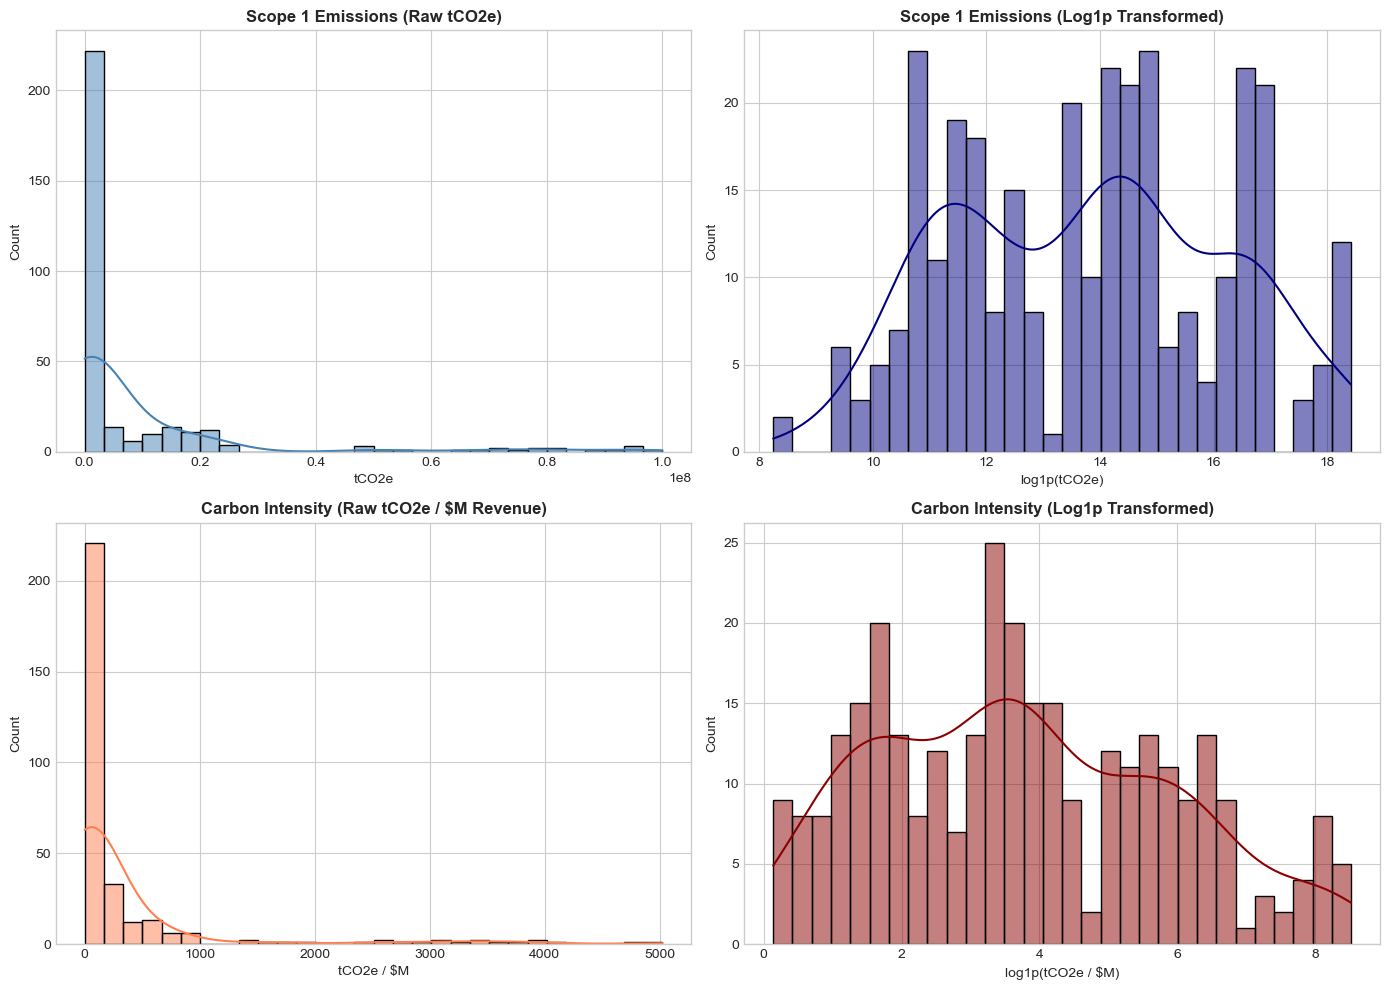

,Metric,Raw Skewness,Log1p Skewness
0,Scope 1 (tCO2e),3.261,0.049
1,Scope 2 Market (tCO2e),4.261,-1.875
2,Revenue ($M),2.708,-0.279
3,Carbon Intensity,3.630,0.303


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Scope 1 Raw vs Log
sns.histplot(df['scope_1_tco2e'], kde=True, ax=axes[0, 0], color='steelblue', bins=30)
axes[0, 0].set_title("Scope 1 Emissions (Raw tCO2e)", fontweight='bold')
axes[0, 0].set_xlabel("tCO2e")

sns.histplot(np.log1p(df['scope_1_tco2e']), kde=True, ax=axes[0, 1], color='navy', bins=30)
axes[0, 1].set_title("Scope 1 Emissions (Log1p Transformed)", fontweight='bold')
axes[0, 1].set_xlabel("log1p(tCO2e)")

# Carbon Intensity Raw vs Log
sns.histplot(df['carbon_intensity_tco2e_per_usd_m'], kde=True, ax=axes[1, 0], color='coral', bins=30)
axes[1, 0].set_title("Carbon Intensity (Raw tCO2e / $M Revenue)", fontweight='bold')
axes[1, 0].set_xlabel("tCO2e / $M")

sns.histplot(np.log1p(df['carbon_intensity_tco2e_per_usd_m']), kde=True, ax=axes[1, 1], color='darkred', bins=30)
axes[1, 1].set_title("Carbon Intensity (Log1p Transformed)", fontweight='bold')
axes[1, 1].set_xlabel("log1p(tCO2e / $M)")

plt.tight_layout()
fig1_path = os.path.join(FIG_DIR, '01_univariate_distributions.png')
plt.savefig(fig1_path, dpi=300)
plt.show()

# Skewness comparison
skew_report = pd.DataFrame({
    'Metric': ['Scope 1 (tCO2e)', 'Scope 2 Market (tCO2e)', 'Revenue ($M)', 'Carbon Intensity'],
    'Raw Skewness': [
        df['scope_1_tco2e'].skew(),
        df['scope_2_market_tco2e'].dropna().skew(),
        df['revenue_usd_m'].skew(),
        df['carbon_intensity_tco2e_per_usd_m'].skew()
    ],
    'Log1p Skewness': [
        np.log1p(df['scope_1_tco2e']).skew(),
        np.log1p(df['scope_2_market_tco2e'].dropna()).skew(),
        np.log1p(df['revenue_usd_m']).skew(),
        np.log1p(df['carbon_intensity_tco2e_per_usd_m']).skew()
    ]
})
skew_report.round(3)

In [3]:
# Percentile breakdown per sector
sector_percentiles = df.groupby('sector')['carbon_intensity_tco2e_per_usd_m'].describe(
    percentiles=[0.25, 0.5, 0.75]
)[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)
sector_percentiles.sort_values(by='50%', ascending=False)

,count,mean,std,min,25%,50%,75%,max
sector,,,,,,,,
Materials,10.0,2894.72,1736.12,462.62,1220.48,3221.51,4047.78,5022.95
Utilities,25.0,1861.69,1188.12,463.71,798.75,1639.76,2747.34,3932.02
Mining & Metals,10.0,566.52,260.07,274.14,331.07,550.96,682.85,1004.32
Energy,25.0,341.97,172.98,133.97,222.45,309.34,423.32,867.76
Transportation,15.0,366.27,221.87,168.73,201.77,259.17,543.21,864.50
Consumer Discretionary,10.0,90.04,87.07,6.63,8.78,79.77,165.75,206.46
Consumer Staples,13.0,79.19,25.86,51.83,58.34,74.56,87.17,133.75
Real Estate,15.0,40.08,31.25,2.98,4.91,43.07,71.99,79.26
Industrials,23.0,70.05,57.98,10.02,35.28,42.95,77.39,187.30


## 2. Sector-Level Comparative Analysis
Comparing operational carbon intensities across all 16 economic sectors and identifying corporate leaders and laggards.

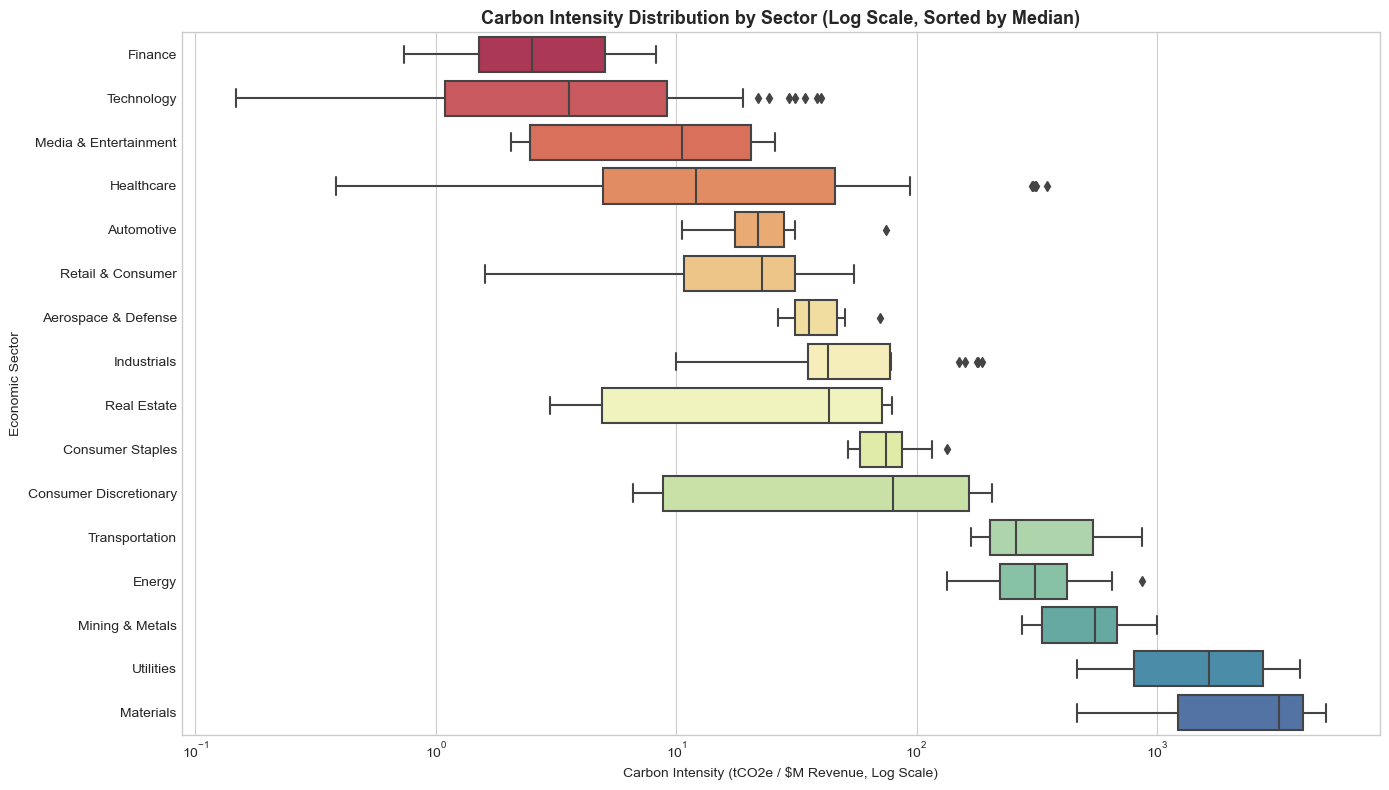

In [4]:
sector_order = df.groupby('sector')['carbon_intensity_tco2e_per_usd_m'].median().sort_values().index

plt.figure(figsize=(14, 8))
sns.boxplot(
    data=df,
    y='sector',
    x='carbon_intensity_tco2e_per_usd_m',
    order=sector_order,
    palette='Spectral'
)
plt.xscale('log')
plt.title("Carbon Intensity Distribution by Sector (Log Scale, Sorted by Median)", fontsize=13, fontweight='bold')
plt.xlabel("Carbon Intensity (tCO2e / $M Revenue, Log Scale)")
plt.ylabel("Economic Sector")
plt.tight_layout()
fig2_path = os.path.join(FIG_DIR, '02_sector_intensity_boxplot.png')
plt.savefig(fig2_path, dpi=300)
plt.show()

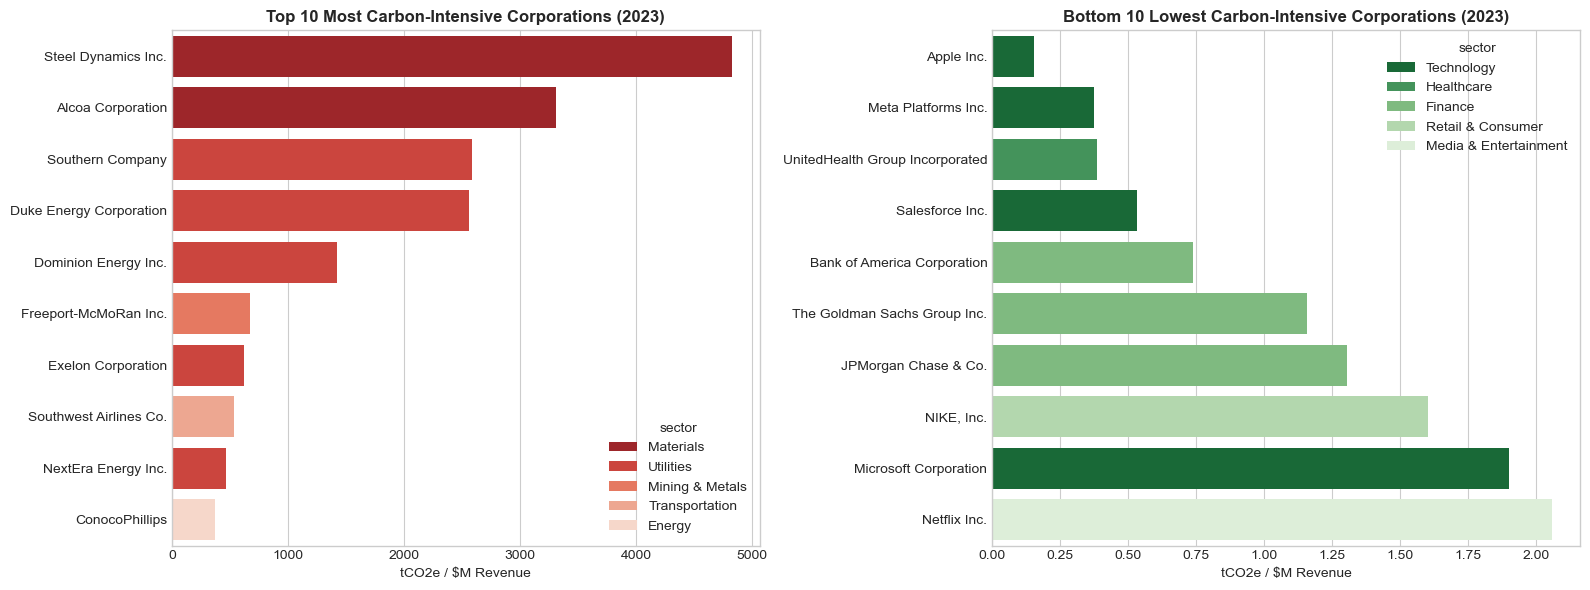

In [5]:
# Outlier identification: Top 10 and Bottom 10 Carbon-Intensive Companies in 2023
df_2023 = df[df['reporting_year'] == 2023].copy()
top10 = df_2023.nlargest(10, 'carbon_intensity_tco2e_per_usd_m')
bot10 = df_2023.nsmallest(10, 'carbon_intensity_tco2e_per_usd_m')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top10, y='company_name', x='carbon_intensity_tco2e_per_usd_m', hue='sector', dodge=False, ax=ax1, palette='Reds_r')
ax1.set_title("Top 10 Most Carbon-Intensive Corporations (2023)", fontweight='bold')
ax1.set_xlabel("tCO2e / $M Revenue")
ax1.set_ylabel("")

sns.barplot(data=bot10, y='company_name', x='carbon_intensity_tco2e_per_usd_m', hue='sector', dodge=False, ax=ax2, palette='Greens_r')
ax2.set_title("Bottom 10 Lowest Carbon-Intensive Corporations (2023)", fontweight='bold')
ax2.set_xlabel("tCO2e / $M Revenue")
ax2.set_ylabel("")

plt.tight_layout()
fig3_path = os.path.join(FIG_DIR, '03_top_bottom_intensity_2023.png')
plt.savefig(fig3_path, dpi=300)
plt.show()

## 3. Multi-Year Trend Analysis (FY2019–FY2023)
Analyzing multi-year trajectory patterns, clean energy transition impacts, and COVID-19 pandemic effects.

C:\Users\MYPC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\MYPC\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


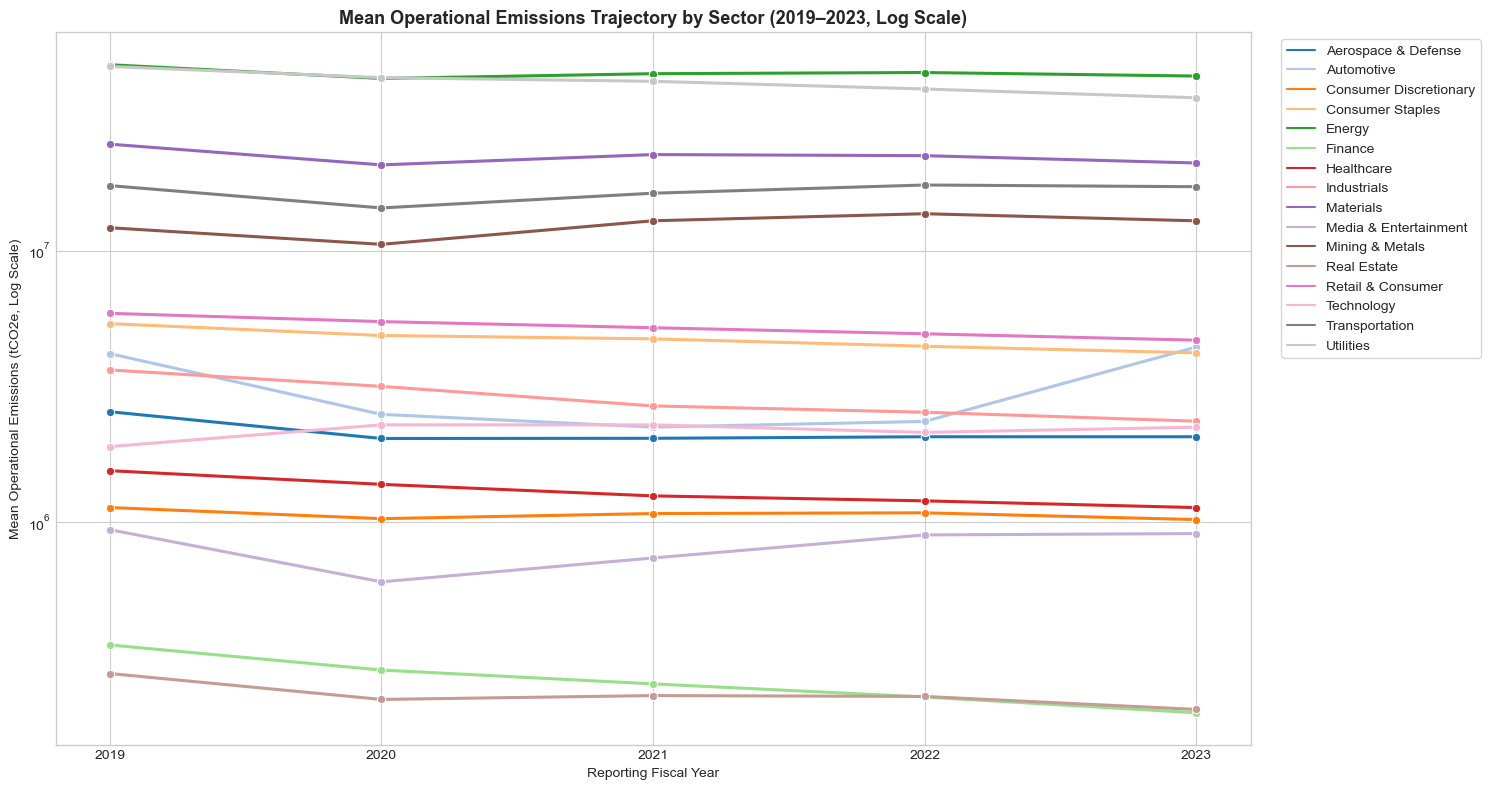

In [6]:
trend_df = df.groupby(['sector', 'reporting_year'])['total_emissions_tco2e'].mean().reset_index()

plt.figure(figsize=(15, 8))
sns.lineplot(
    data=trend_df,
    x='reporting_year',
    y='total_emissions_tco2e',
    hue='sector',
    marker='o',
    linewidth=2.2,
    palette='tab20'
)
plt.yscale('log')
plt.title("Mean Operational Emissions Trajectory by Sector (2019–2023, Log Scale)", fontsize=13, fontweight='bold')
plt.xlabel("Reporting Fiscal Year")
plt.ylabel("Mean Operational Emissions (tCO2e, Log Scale)")
plt.xticks([2019, 2020, 2021, 2022, 2023])
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
fig4_path = os.path.join(FIG_DIR, '04_emissions_trends_by_sector.png')
plt.savefig(fig4_path, dpi=300)
plt.show()

In [7]:
# Mean annual emissions reduction percentage across sectors (2019 vs 2023)
pivot_emissions = df.pivot_table(index='sector', columns='reporting_year', values='total_emissions_tco2e', aggfunc='mean')
if 2019 in pivot_emissions.columns and 2023 in pivot_emissions.columns:
    pivot_emissions['Overall_Change_%'] = ((pivot_emissions[2023] - pivot_emissions[2019]) / pivot_emissions[2019] * 100).round(2)
pivot_emissions.round(1)

reporting_year,2019,2020,2021,2022,2023,Overall_Change_%
sector,,,,,,
Aerospace & Defense,2543333.3,2026666.7,2030000.0,2056666.7,2056666.7,-19.1
Automotive,4165000.0,2487000.0,2232666.7,2342333.3,4404666.7,5.8
Consumer Discretionary,1127500.0,1026000.0,1071500.0,1078000.0,1018000.0,-9.7
Consumer Staples,5375000.0,4860000.0,4723333.3,4436666.7,4193333.3,-22.0
Energy,48444000.0,43118000.0,44900000.0,45344000.0,44004000.0,-9.2
Finance,350900.0,283640.0,252160.0,225620.0,197320.0,-43.8
Healthcare,1541714.3,1373000.0,1244737.5,1193384.0,1127090.8,-26.9
Industrials,3627500.0,3155000.0,2672887.4,2533219.6,2347359.6,-35.3
Materials,24680000.0,20695000.0,22590000.0,22380000.0,21030000.0,-14.8


## 4. Scope 3 Value-Chain Assessment
Evaluating Scope 3 disclosure rates and calculating the value-chain leverage multiplier (Scope 3 relative to operational Scope 1+2).

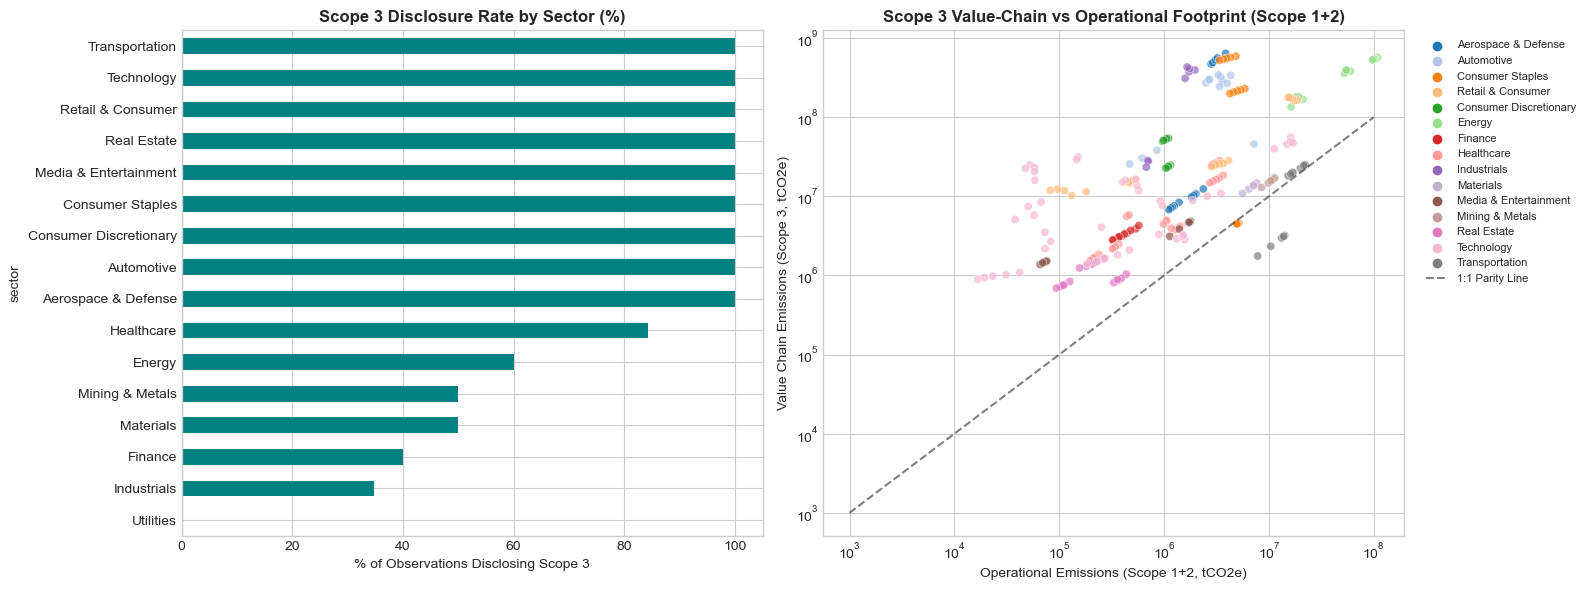

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Coverage percentage per sector
s3_cov = df.groupby('sector')['scope_3_tco2e'].apply(lambda x: x.notnull().mean() * 100).sort_values()
s3_cov.plot(kind='barh', ax=ax1, color='teal')
ax1.set_title("Scope 3 Disclosure Rate by Sector (%)", fontweight='bold')
ax1.set_xlabel("% of Observations Disclosing Scope 3")
ax1.set_xlim(0, 105)

# Scatter: Scope 3 vs Scope 1+2
s3_valid = df[df['scope_3_tco2e'].notnull() & (df['total_emissions_tco2e'] > 0)].copy()
sns.scatterplot(
    data=s3_valid,
    x='total_emissions_tco2e',
    y='scope_3_tco2e',
    hue='sector',
    alpha=0.7,
    ax=ax2,
    palette='tab20'
)
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.plot([1e3, 1e8], [1e3, 1e8], 'k--', alpha=0.5, label='1:1 Parity Line')
ax2.set_title("Scope 3 Value-Chain vs Operational Footprint (Scope 1+2)", fontweight='bold')
ax2.set_xlabel("Operational Emissions (Scope 1+2, tCO2e)")
ax2.set_ylabel("Value Chain Emissions (Scope 3, tCO2e)")
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.tight_layout()
fig5_path = os.path.join(FIG_DIR, '05_scope3_analysis.png')
plt.savefig(fig5_path, dpi=300)
plt.show()

## 5. Correlation Analysis
Assessing linear dependencies and multicollinearity across primary regulatory financials and greenhouse gas disclosures.

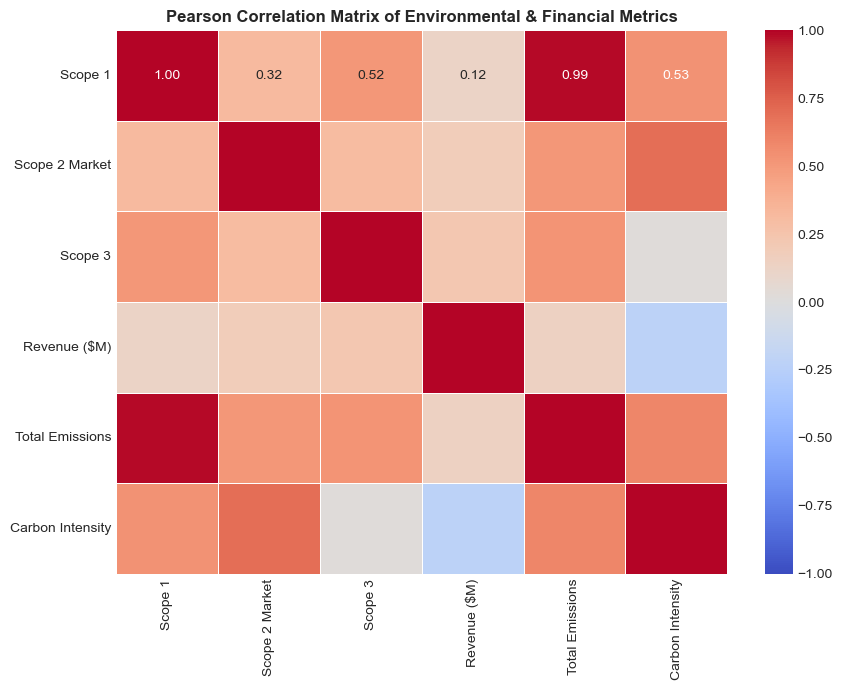

In [9]:
corr_cols = [
    'scope_1_tco2e', 'scope_2_market_tco2e', 'scope_3_tco2e',
    'revenue_usd_m', 'total_emissions_tco2e', 'carbon_intensity_tco2e_per_usd_m'
]
corr_labels = ['Scope 1', 'Scope 2 Market', 'Scope 3', 'Revenue ($M)', 'Total Emissions', 'Carbon Intensity']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    xticklabels=corr_labels,
    yticklabels=corr_labels,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Pearson Correlation Matrix of Environmental & Financial Metrics", fontsize=12, fontweight='bold')
plt.tight_layout()
fig6_path = os.path.join(FIG_DIR, '06_correlation_matrix.png')
plt.savefig(fig6_path, dpi=300)
plt.show()

## 6. Feature Engineering & Target Label Formulation
Engineering the formal feature set and sector-adjusted tertile classification targets for Module 2, 3, and 4.

In [10]:
# 1. Log transformations
s2_effective = df['scope_2_market_tco2e'].fillna(df['scope_2_location_tco2e']).fillna(0.0)
df['log_scope1'] = np.log1p(df['scope_1_tco2e'])
df['log_scope2'] = np.log1p(s2_effective)
df['log_revenue'] = np.log1p(df['revenue_usd_m'])

# 2. Ratios and shares
df['scope1_share'] = (df['scope_1_tco2e'] / df['total_emissions_tco2e'].replace(0, np.nan)).fillna(0.0)
df['scope3_ratio'] = (df['scope_3_tco2e'] / df['total_emissions_tco2e'].replace(0, np.nan))
s3_median_by_sec = df.groupby('sector')['scope3_ratio'].transform('median')
df['scope3_ratio_imputed'] = df['scope3_ratio'].fillna(s3_median_by_sec).fillna(df['scope3_ratio'].median())

# 3. Lag and YoY features
df['intensity_lag1'] = df.groupby('company_id')['carbon_intensity_tco2e_per_usd_m'].shift(1)
df['yoy_intensity_change'] = (df['carbon_intensity_tco2e_per_usd_m'] - df['intensity_lag1']).fillna(0.0)

# 4. Scope 2 reduction relative to company baseline
def calc_s2_reduction(grp):
    s2_vals = grp['scope_2_market_tco2e'].fillna(grp['scope_2_location_tco2e']).fillna(0.0)
    baseline = s2_vals.iloc[0]
    if baseline > 0:
        return (baseline - s2_vals) / baseline
    return pd.Series(0.0, index=grp.index)

df['scope2_reduction'] = df.groupby('company_id', group_keys=False).apply(calc_s2_reduction)

# 5. Sector benchmarks
df['sector_median_intensity'] = df.groupby(['sector', 'reporting_year'])['carbon_intensity_tco2e_per_usd_m'].transform('median')
df['intensity_vs_sector_median'] = df['carbon_intensity_tco2e_per_usd_m'] - df['sector_median_intensity']

# 6. Sector-relative tertiles for intensity label
def assign_sector_tertiles(grp):
    ranks = grp['carbon_intensity_tco2e_per_usd_m'].rank(pct=True, method='average')
    labels = pd.Series('Moderate', index=grp.index)
    labels[ranks <= (1.0/3.0)] = 'Low'
    labels[ranks > (2.0/3.0)] = 'High'
    return labels

df['intensity_label'] = df.groupby('sector', group_keys=False).apply(assign_sector_tertiles)

print("Engineered Feature Matrix Columns:")
print(df[['log_scope1', 'log_scope2', 'log_revenue', 'scope1_share', 'scope3_ratio_imputed', 'yoy_intensity_change', 'scope2_reduction', 'intensity_label']].head(6))

Engineered Feature Matrix Columns:
   log_scope1  log_scope2  log_revenue  scope1_share  scope3_ratio_imputed  \
0   14.907434   13.698978    11.245830      0.770026            165.374677   
1   14.599413   13.337476    10.970936      0.779359            167.259786   
2   14.639686   13.369225    11.039508      0.780822            167.808219   
3   14.695138   13.429850    11.106595      0.779935            171.521036   
4   14.739770   13.473022    11.261832      0.780186            173.374613   
5   13.664689   13.180634    10.429458      0.618705              6.043165   

   yoy_intensity_change  scope2_reduction intensity_label  
0                0.0000          0.000000            High  
1               -2.2325          0.303371            High  
2               -1.4362          0.280899            High  
3               -0.4897          0.235955            High  
4               -4.8709          0.202247        Moderate  
5                0.0000          0.000000        Moderate 

In [11]:
# Export features.csv and labels.csv
DATA_PROCESSED = os.path.join('..', 'data', 'processed')

feature_cols = [
    'company_id', 'company_name', 'ticker_or_lei', 'sector', 'reporting_year',
    'scope_1_tco2e', 'scope_2_market_tco2e', 'scope_3_tco2e', 'revenue_usd_m',
    'total_emissions_tco2e', 'carbon_intensity_tco2e_per_usd_m',
    'log_scope1', 'log_scope2', 'log_revenue', 'scope1_share',
    'scope3_ratio_imputed', 'yoy_intensity_change', 'scope2_reduction',
    'sector_median_intensity', 'intensity_vs_sector_median'
]
df_features = df[feature_cols].copy()
features_out = os.path.join(DATA_PROCESSED, 'features.csv')
df_features.to_csv(features_out, index=False)

label_cols = [
    'company_id', 'company_name', 'sector', 'reporting_year',
    'carbon_intensity_tco2e_per_usd_m', 'intensity_label'
]
df_labels = df[label_cols].copy()
labels_out = os.path.join(DATA_PROCESSED, 'labels.csv')
df_labels.to_csv(labels_out, index=False)

print(f"Successfully exported {features_out} ({df_features.shape[0]} rows x {df_features.shape[1]} cols)")
print(f"Successfully exported {labels_out} ({df_labels.shape[0]} rows x {df_labels.shape[1]} cols)")

# Quality check on exported artifacts
assert df_features.isnull().sum()['log_scope1'] == 0, "Missing log_scope1!"
assert df_features.isnull().sum()['log_revenue'] == 0, "Missing log_revenue!"
assert df_labels['intensity_label'].isnull().sum() == 0, "Missing intensity labels!"
print("All feature and label consistency assertions PASSED.")

Successfully exported ..\data\processed\features.csv (313 rows x 20 cols)
Successfully exported ..\data\processed\labels.csv (313 rows x 6 cols)
All feature and label consistency assertions PASSED.
